In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
import pandas as pd
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *


In [2]:
#domainM='GRp';domain='GRf';spin='spin2'
#nx=10;ny=10
iyr=2000
fyr=2016

In [3]:
#resultsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/compu_results/'
#ds1 = xr.open_dataset(resultsDir+f"snowline_df1_mask70_MAR_GRp_2000-2016.nc")
#ds2 = xr.open_dataset(resultsDir+f"snowline_df1_mask_nosnow_0.001_ESACCI_GRp_2000-2016.nc")
#ds3 = xr.open_dataset(resultsDir+f"snowline_df1_mask70_ERA5L_GRp_2000-2016.nc")
#ds4 = xr.open_dataset(resultsDir+f"snowline_df1_mask70_HMASR_GRp_2000-2016.nc")
#ds7 = xr.open_dataset(resultsDir+f"snowline_df1_HARv2_GRp_2000-2016.nc")
#ds1_q = xr.open_dataset(resultsDir+f"snowline_df1_mask70_MAR_GRq_2000-2016.nc")
#ds2_q = xr.open_dataset(resultsDir+f"snowline_df1_mask_nosnow_0.001_ESACCI_GRq_2000-2016.nc")
#ds3_q = xr.open_dataset(resultsDir+f"snowline_df1_mask70_ERA5L_GRq_2000-2016.nc")
#ds4_q = xr.open_dataset(resultsDir+f"snowline_df1_mask70_HMASR_GRq_2000-2016.nc")
#ds7_q = xr.open_dataset(resultsDir+f"snowline_df1_HARv2_GRq_2000-2016.nc")

In [4]:
#!ls /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/compu_results/sno*GRp*2000*2016*


Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSupport7_annual_cycle_snowline_met_0.01_10_2000-2016.png


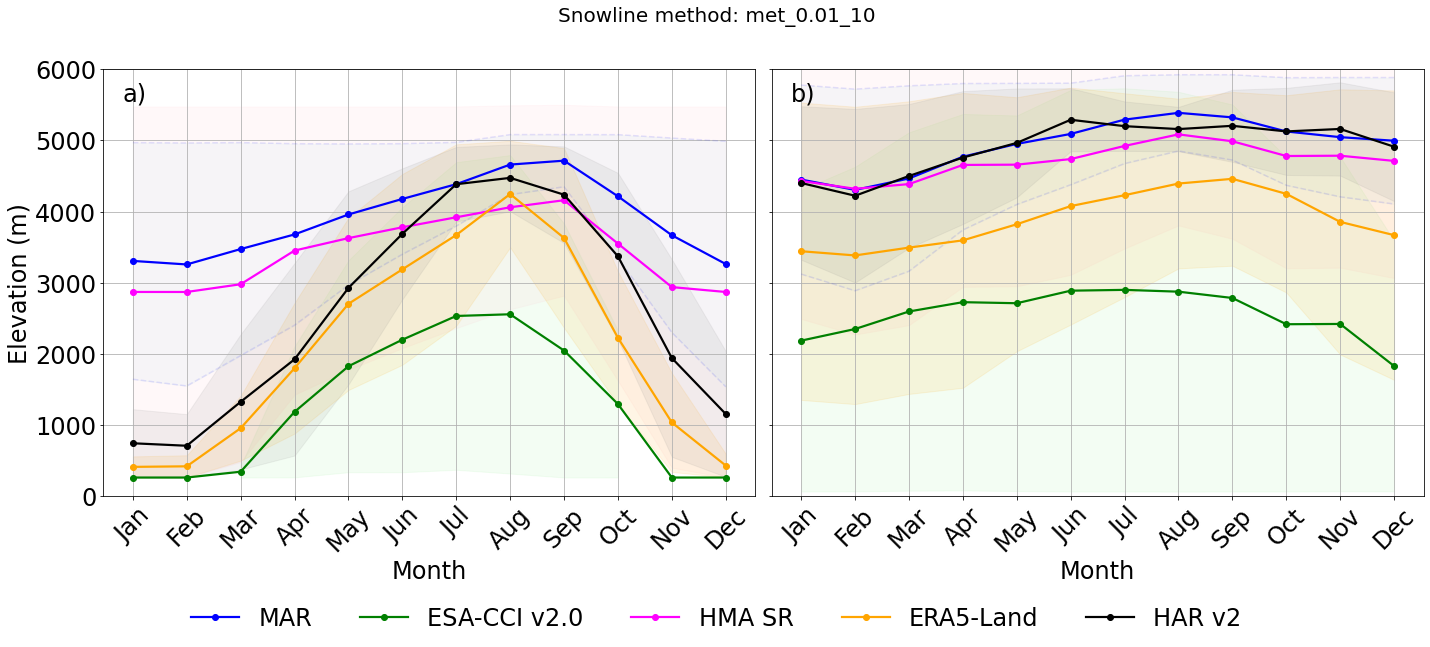

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSupport7_annual_cycle_snowline_met_0.01_100_2000-2016.png


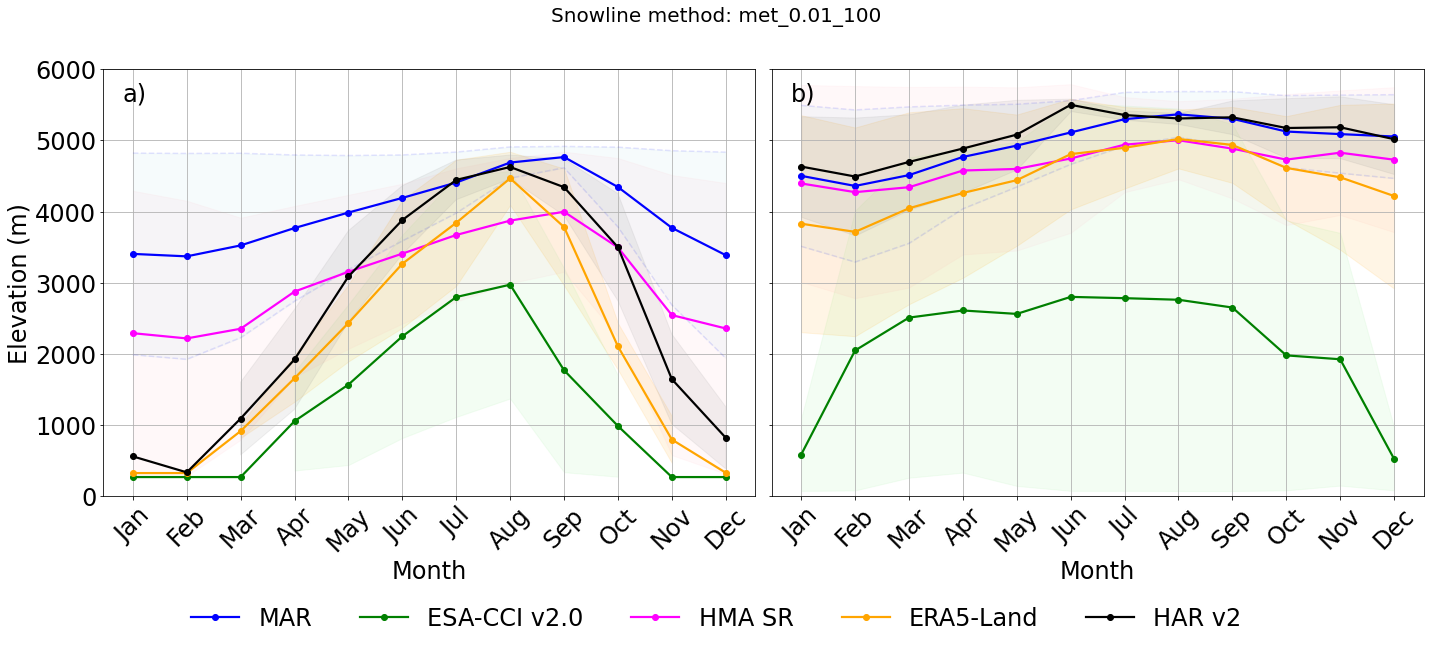

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSupport7_annual_cycle_snowline_met_0.01_1000_2000-2016.png


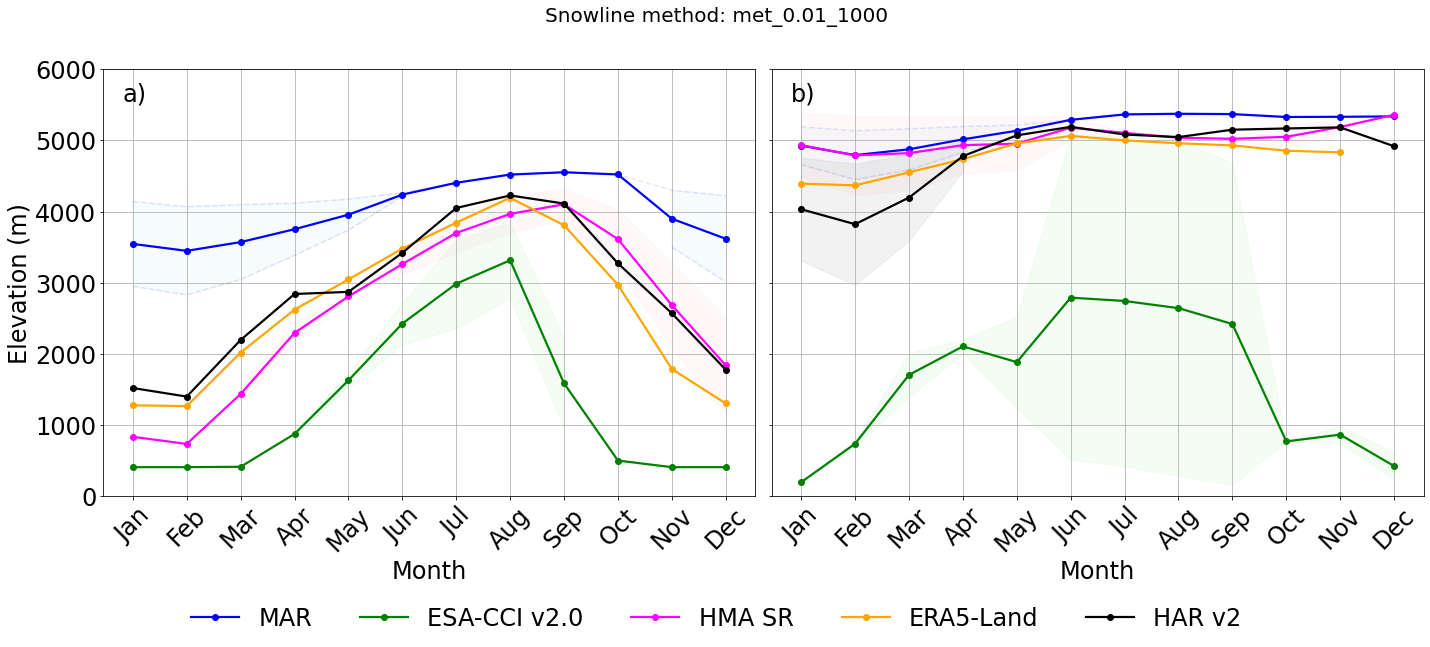

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSupport7_annual_cycle_snowline_met_0.1_10_2000-2016.png


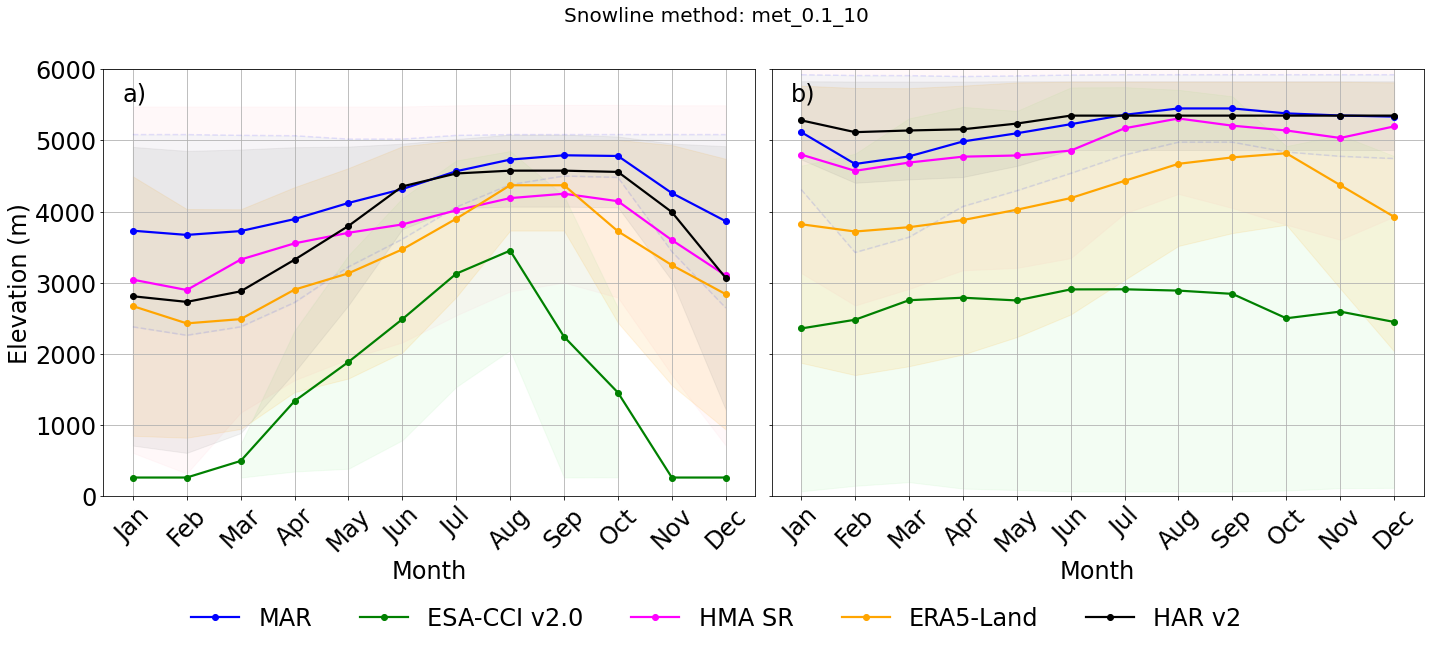

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSupport7_annual_cycle_snowline_met_0.1_100_2000-2016.png


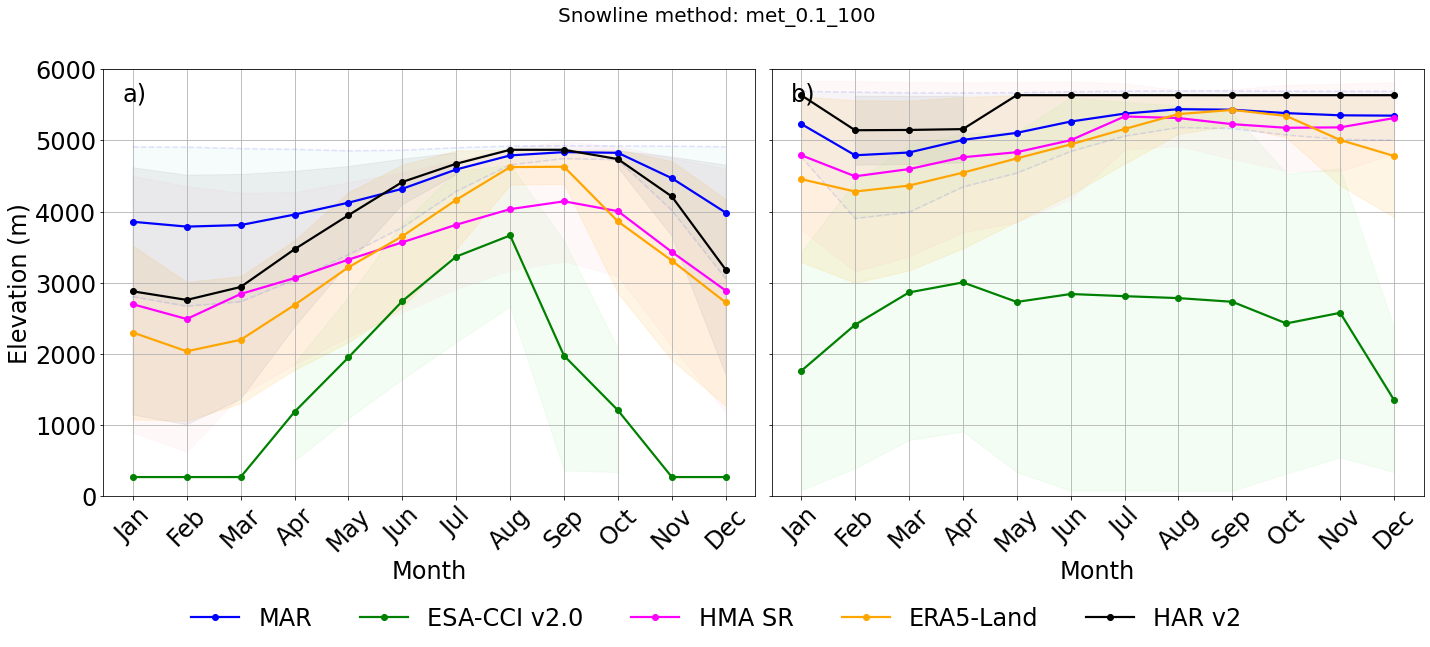

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSupport7_annual_cycle_snowline_met_0.1_1000_2000-2016.png


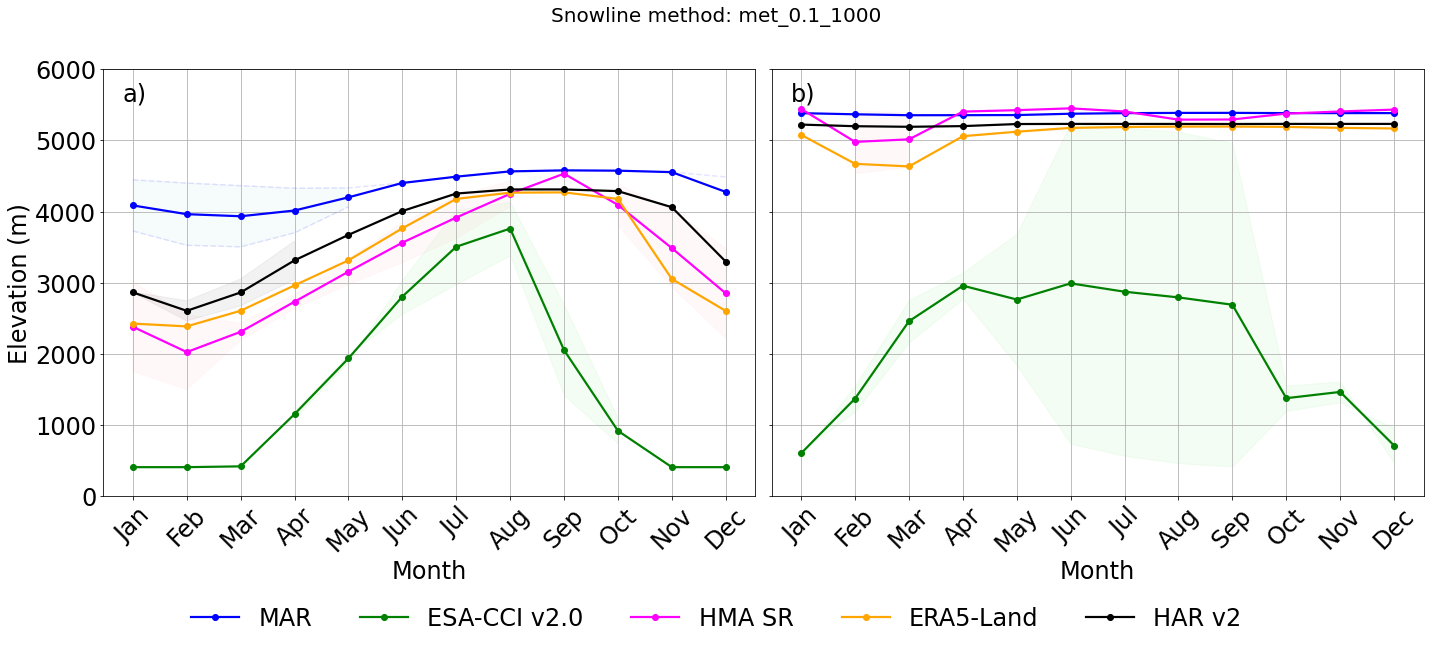

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSupport7_annual_cycle_snowline_met_0.5_10_2000-2016.png


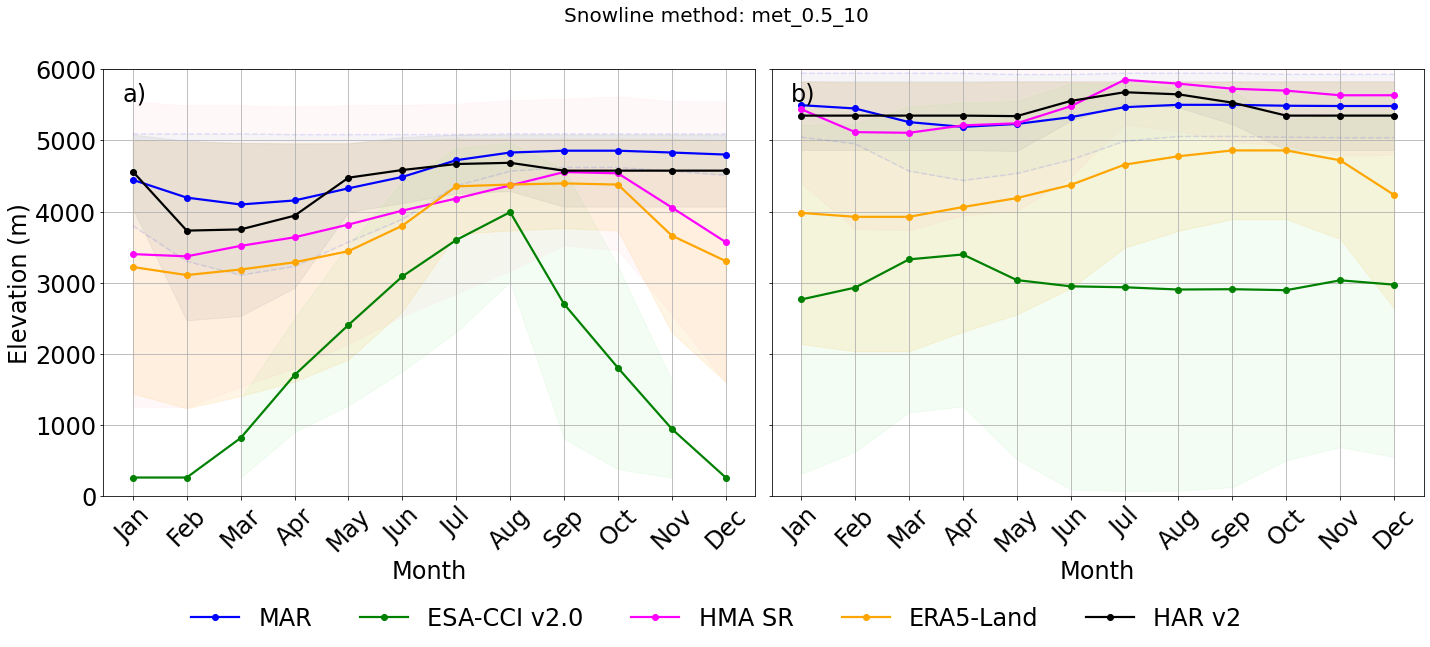

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIGSupport7_annual_cycle_snowline_met_0.5_100_2000-2016.png


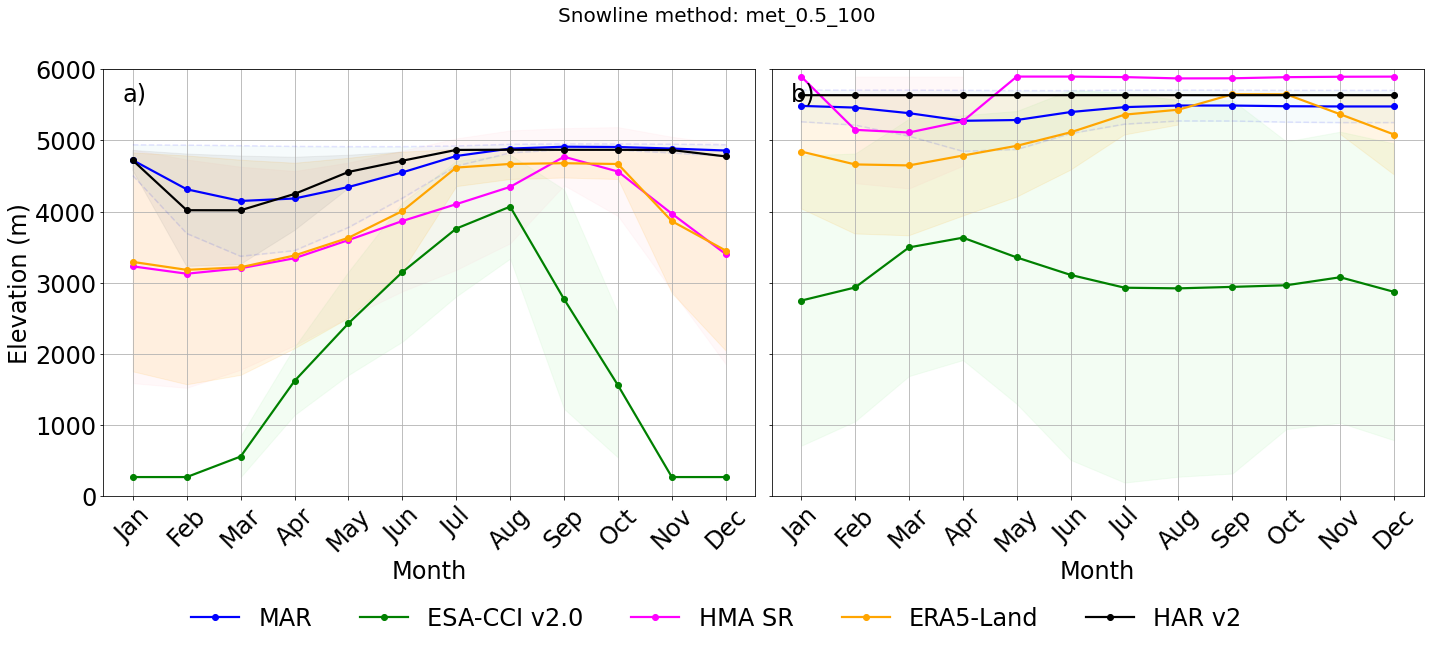

In [5]:


resultsDir="/home/santolam/RECAP/results/snowline_tables/"

methods = [
    "met_0.01_10",
    "met_0.01_100",
    "met_0.01_1000",
    "met_0.1_10",
    "met_0.1_100",
    "met_0.1_1000",
    "met_0.5_10",
    "met_0.5_100",
]
for method in methods:

    # =========================
    # Read GRp
    # =========================
    ds1 = pd.read_csv(f"{resultsDir}/snowline_MAR_GRp_{method}.csv")
    ds2 = pd.read_csv(f"{resultsDir}/snowline_ESACCI_GRp_{method}.csv")
    ds3 = pd.read_csv(f"{resultsDir}/snowline_era5-land_GRp_{method}.csv")
    ds4 = pd.read_csv(f"{resultsDir}/snowline_HMASR_GRp_{method}.csv")
    ds7 = pd.read_csv(f"{resultsDir}/snowline_HARv2_GRp_{method}.csv")

    # =========================
    # Read GRq
    # =========================
    ds1_q = pd.read_csv(f"{resultsDir}/snowline_MAR_GRq_{method}.csv")
    ds2_q = pd.read_csv(f"{resultsDir}/snowline_ESACCI_GRq_{method}.csv")
    ds3_q = pd.read_csv(f"{resultsDir}/snowline_era5-land_GRq_{method}.csv")
    ds4_q = pd.read_csv(f"{resultsDir}/snowline_HMASR_GRq_{method}.csv")
    ds7_q = pd.read_csv(f"{resultsDir}/snowline_HARv2_GRq_{method}.csv")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,8), sharey=True)

    # =========================
    # LEFT PANEL : GRp
    # =========================

    # MAR
    ax1.plot(ds1['month'], ds1['mean_snowline'],
             marker='o', color="blue", linewidth=2.2, label="MAR")
    ax1.plot(ds1['month'], ds1['mean_bottom10'], "--",
             color="blue", alpha=0.1)
    ax1.plot(ds1['month'], ds1['mean_top10'], "--",
             color="blue", alpha=0.1)
    ax1.fill_between(ds1['month'], ds1['mean_bottom10'],
                     ds1['mean_top10'],
                     color="lightblue", alpha=0.1)

    # ESA CCI
    ax1.plot(ds2['month'], ds2['mean_snowline'],
             marker='o', color="green", linewidth=2.2,
             label="ESA-CCI v2.0")
    ax1.fill_between(ds2['month'], ds2['mean_bottom10'],
                     ds2['mean_top10'],
                     color="lightgreen", alpha=0.1)

    # HMA SR
    ax1.plot(ds4['month'], ds4['mean_snowline'],
             marker='o', color="fuchsia", linewidth=2.2,
             label="HMA SR")
    ax1.fill_between(ds4['month'], ds4['mean_bottom10'],
                     ds4['mean_top10'],
                     color="pink", alpha=0.1)

    # ERA5-Land
    ax1.plot(ds3['month'], ds3['mean_snowline'],
             marker='o', color="orange", linewidth=2.2,
             label="ERA5-Land")
    ax1.fill_between(ds3['month'], ds3['mean_bottom10'],
                     ds3['mean_top10'],
                     color="orange", alpha=0.1)

    # HAR v2
    ax1.plot(ds7['month'], ds7['mean_snowline'],
             marker='o', color="black", linewidth=2.2,
             label="HAR v2")
    ax1.fill_between(ds7['month'], ds7['mean_bottom10'],
                     ds7['mean_top10'],
                     color="grey", alpha=0.1)

    ax1.set_xlabel('Month', fontsize=24)
    ax1.set_xticks(np.arange(1, 13, 1))
    ax1.set_xticklabels(
        ['Jan','Feb','Mar','Apr','May','Jun',
         'Jul','Aug','Sep','Oct','Nov','Dec'],
        rotation=45,
        fontsize=24
    )
    ax1.tick_params(axis='x', rotation=45, labelsize=24)
    ax1.tick_params(axis='y', labelsize=24)

    ax1.set_ylim(0,6000)
    ax1.set_ylabel('Elevation (m)', fontsize=24)

    ax1.text(0.03, 0.97, 'a)', fontsize=24,
             transform=ax1.transAxes,
             horizontalalignment='left',
             verticalalignment='top')

    ax1.grid(True)

    # =========================
    # RIGHT PANEL : GRq
    # =========================

    # MAR
    ax2.plot(ds1_q['month'], ds1_q['mean_snowline'],
             marker='o', color="blue", linewidth=2.2, label="MAR")
    ax2.plot(ds1_q['month'], ds1_q['mean_bottom10'], "--",
             color="blue", alpha=0.1)
    ax2.plot(ds1_q['month'], ds1_q['mean_top10'], "--",
             color="blue", alpha=0.1)
    ax2.fill_between(ds1_q['month'], ds1_q['mean_bottom10'],
                     ds1_q['mean_top10'],
                     color="lightblue", alpha=0.1)

    # ESA CCI
    ax2.plot(ds2_q['month'], ds2_q['mean_snowline'],
             marker='o', color="green", linewidth=2.2,
             label="ESA-CCI v2.0")
    ax2.fill_between(ds2_q['month'], ds2_q['mean_bottom10'],
                     ds2_q['mean_top10'],
                     color="lightgreen", alpha=0.1)

    # HMA SR
    
    ax2.plot(ds4_q['month'], ds4_q['mean_snowline'],
             marker='o', color="fuchsia", linewidth=2.2,
             label="HMA SR")
    ax2.fill_between(ds4_q['month'], ds4_q['mean_bottom10'],
                     ds4_q['mean_top10'],
                     color="pink", alpha=0.1)

    # ERA5-Land
    ax2.plot(ds3_q['month'], ds3_q['mean_snowline'],
             marker='o', color="orange", linewidth=2.2,
             label="ERA5-Land")
    ax2.fill_between(ds3_q['month'], ds3_q['mean_bottom10'],
                     ds3_q['mean_top10'],
                     color="orange", alpha=0.1)

    # HAR v2
    ax2.plot(ds7_q['month'], ds7_q['mean_snowline'],
             marker='o', color="black", linewidth=2.2,
              label="HAR v2")
    ax2.fill_between(ds7_q['month'], ds7_q['mean_bottom10'],
                     ds7_q['mean_top10'],
                     color="grey", alpha=0.1)

    ax2.set_xlabel('Month', fontsize=24)
    ax2.set_xticks(np.arange(1, 13, 1))
    ax2.set_xticklabels(
        ['Jan','Feb','Mar','Apr','May','Jun',
         'Jul','Aug','Sep','Oct','Nov','Dec'],
        rotation=45,
        fontsize=16
    )

    ax2.tick_params(axis='x', rotation=45, labelsize=24)
    ax2.tick_params(axis='y', labelsize=24)

    ax2.set_ylim(0,6000)

    ax2.text(0.03, 0.97, 'b)', fontsize=24,
             transform=ax2.transAxes,
             horizontalalignment='left',
             verticalalignment='top')

    ax2.grid(True)

    # =========================
    # LEGEND + SAVE
    # =========================
    fig.suptitle(f"Snowline method: {method}", fontsize=20, y=1.02)
    handles, labels = ax1.get_legend_handles_labels()

    fig.legend(handles, labels,
               loc='lower center',
               ncol=5,
               fontsize=24,
               frameon=False,
               bbox_to_anchor=(0.5, -0.10))

    plt.tight_layout()

    plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
    plotname=f"FIGSupport7_annual_cycle_snowline_{method}_{iyr}-{fyr}"

    plt.savefig(f"{plotsDir}{plotname}.png",
                bbox_inches="tight", dpi=300)

    print(f"Saved: {plotsDir}{plotname}.png")

    plt.show()

In [6]:
methods = [
    "met_0.01_10",
    "met_0.01_100",
    "met_0.01_1000",
    "met_0.1_10",
    "met_0.1_25",
    "met_0.1_50",
    "met_0.1_100",
    "met_0.1_1000",
    "met_0.5_10",
    "met_0.5_100",
]

method25=methods[4]
method50=methods[5]
method100=methods[6]

    # =========================
    # Read GRp
    # =========================
ds1 = pd.read_csv(f"{resultsDir}/snowline_MAR_GRp_{method50}.csv")
ds2 = pd.read_csv(f"{resultsDir}/snowline_ESACCI_GRp_{method100}.csv")
ds3 = pd.read_csv(f"{resultsDir}/snowline_era5-land_GRp_{method25}.csv")
ds4 = pd.read_csv(f"{resultsDir}/snowline_HMASR_GRp_{method50}.csv")
ds7 = pd.read_csv(f"{resultsDir}/snowline_HARv2_GRp_{method25}.csv")

    # =========================
    # Read GRq
    # =========================
ds1_q = pd.read_csv(f"{resultsDir}/snowline_MAR_GRq_{method50}.csv")
ds2_q = pd.read_csv(f"{resultsDir}/snowline_ESACCI_GRq_{method100}.csv")
ds3_q = pd.read_csv(f"{resultsDir}/snowline_era5-land_GRq_{method25}.csv")
ds4_q = pd.read_csv(f"{resultsDir}/snowline_HMASR_GRq_{method50}.csv")
ds7_q = pd.read_csv(f"{resultsDir}/snowline_HARv2_GRq_{method25}.csv")


In [7]:
fz=24

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIG7_annual_cycle_snowline_elevation_pamir_nepal_2000-2016_method_ratio_nbrpix.png


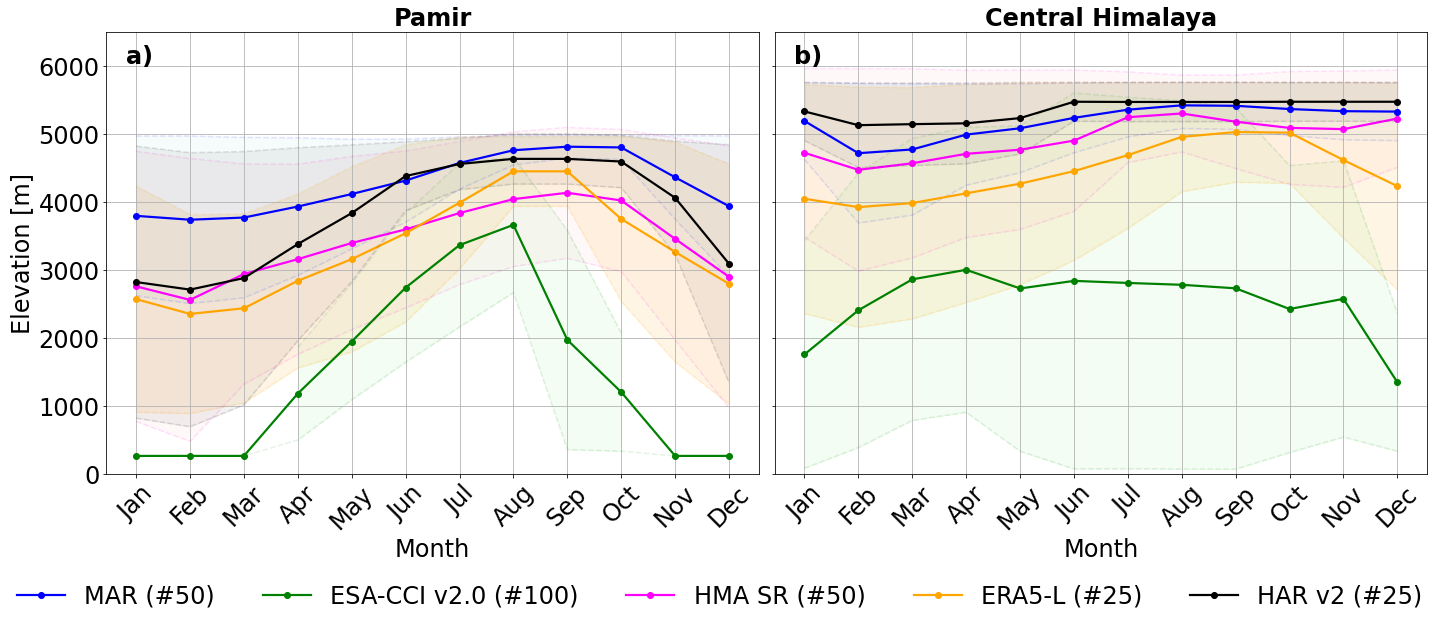

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,8), sharey=True)

# =========================
# LEFT PANEL : GRp
# =========================

# MAR
ax1.plot(ds1['month'], ds1['mean_snowline'],
         marker='o', color="blue", linewidth=2.2, label="MAR (#50)")
ax1.plot(ds1['month'], ds1['mean_bottom10'], "--",
         color="blue", alpha=0.1)
ax1.plot(ds1['month'], ds1['mean_top10'], "--",
         color="blue", alpha=0.1)
ax1.fill_between(ds1['month'], ds1['mean_bottom10'],
                 ds1['mean_top10'],
                 color="lightblue", alpha=0.1)

# ESA CCI
ax1.plot(ds2['month'], ds2['mean_snowline'],
         marker='o', color="green", linewidth=2.2,
         label="ESA-CCI v2.0 (#100)")
ax1.fill_between(ds2['month'], ds2['mean_bottom10'],
                 ds2['mean_top10'],
                 color="lightgreen", alpha=0.1)
ax1.plot(ds2['month'], ds2['mean_bottom10'], "--",
         color="green", alpha=0.1)
ax1.plot(ds2['month'], ds2['mean_top10'], "--",
         color="green", alpha=0.1)

# HMA SR

ax1.plot(ds4['month'], ds4['mean_snowline'],
         marker='o', color="fuchsia", linewidth=2.2,
         label="HMA SR (#50)")
ax1.fill_between(ds4['month'], ds4['mean_bottom10'],
                 ds4['mean_top10'],
                 color="pink", alpha=0.1)
ax1.plot(ds4['month'], ds4['mean_bottom10'], "--",
         color="fuchsia", alpha=0.1)
ax1.plot(ds4['month'], ds4['mean_top10'], "--",
         color="fuchsia", alpha=0.1)

# ERA5-Land
ax1.plot(ds3['month'], ds3['mean_snowline'],
         marker='o', color="orange", linewidth=2.2,
         label="ERA5-L (#25)")
ax1.fill_between(ds3['month'], ds3['mean_bottom10'],
                 ds3['mean_top10'],
                 color="orange", alpha=0.1)
ax1.plot(ds3['month'], ds3['mean_bottom10'], "--",
         color="orange", alpha=0.1)
ax1.plot(ds3['month'], ds3['mean_top10'], "--",
         color="orange", alpha=0.1)

# HAR v2
ax1.plot(ds7['month'], ds7['mean_snowline'],
         marker='o', color="black", linewidth=2.2,
         label="HAR v2 (#25)")
ax1.fill_between(ds7['month'], ds7['mean_bottom10'],
                 ds7['mean_top10'],
                 color="grey", alpha=0.1)
ax1.plot(ds7['month'], ds7['mean_bottom10'], "--",
         color="black", alpha=0.1)
ax1.plot(ds7['month'], ds7['mean_top10'], "--",
         color="black", alpha=0.1)


ax1.set_xlabel('Month', fontsize=fz)
ax1.set_xticks(np.arange(1, 13, 1))
ax1.set_xticklabels(
    ['Jan','Feb','Mar','Apr','May','Jun',
     'Jul','Aug','Sep','Oct','Nov','Dec'],
    rotation=45,
    fontsize=fz
)
ax1.tick_params(axis='x', rotation=45, labelsize=fz)
ax1.tick_params(axis='y', labelsize=fz)

ax1.set_ylim(0,6000)
ax1.set_ylabel('Elevation [m]', fontsize=fz)

ax1.text(0.03, 0.97, 'a)', fontsize=fz,fontweight='bold',
         transform=ax1.transAxes,
         horizontalalignment='left',
         verticalalignment='top')
ax1.set_title( 'Pamir', fontsize=fz,fontweight='bold')
ax1.grid(True)

# =========================
# RIGHT PANEL : GRq
# =========================

# MAR
ax2.plot(ds1_q['month'], ds1_q['mean_snowline'],
         marker='o', color="blue", linewidth=2.2, label="MAR (#50)")
ax2.plot(ds1_q['month'], ds1_q['mean_bottom10'], "--",
         color="blue", alpha=0.1)
ax2.plot(ds1_q['month'], ds1_q['mean_top10'], "--",
         color="blue", alpha=0.1)
ax2.fill_between(ds1_q['month'], ds1_q['mean_bottom10'],
                 ds1_q['mean_top10'],
                 color="lightblue", alpha=0.1)

# ESA CCI
ax2.plot(ds2_q['month'], ds2_q['mean_snowline'],
         marker='o', color="green", linewidth=2.2,
         label="ESA-CCI v2.0 (#100)")
ax2.fill_between(ds2_q['month'], ds2_q['mean_bottom10'],
                 ds2_q['mean_top10'],
                 color="lightgreen", alpha=0.1)
ax2.plot(ds2_q['month'], ds2_q['mean_bottom10'], "--",
         color="green", alpha=0.1)
ax2.plot(ds2_q['month'], ds2_q['mean_top10'], "--",
         color="green", alpha=0.1)

# HMA SR
ax2.plot(ds4_q['month'], ds4_q['mean_snowline'],
         marker='o', color="fuchsia", linewidth=2.2,
         label="HMA SR (#50)")
ax2.fill_between(ds4_q['month'], ds4_q['mean_bottom10'],
                 ds4_q['mean_top10'],
                 color="pink", alpha=0.1)
ax2.plot(ds4_q['month'], ds4_q['mean_bottom10'], "--",
         color="fuchsia", alpha=0.1)
ax2.plot(ds4_q['month'], ds4_q['mean_top10'], "--",
         color="fuchsia", alpha=0.1)

# ERA5-Land
ax2.plot(ds3_q['month'], ds3_q['mean_snowline'],
         marker='o', color="orange", linewidth=2.2,
         label="ERA5-L (#25)")
ax2.fill_between(ds3_q['month'], ds3_q['mean_bottom10'],
                 ds3_q['mean_top10'],
                 color="orange", alpha=0.1)
ax2.plot(ds3_q['month'], ds3_q['mean_bottom10'], "--",
         color="orange", alpha=0.1)
ax2.plot(ds3_q['month'], ds3_q['mean_top10'], "--",
         color="orange", alpha=0.1)

# HAR v2
ax2.plot(ds7_q['month'], ds7_q['mean_snowline'],
         marker='o', color="black", linewidth=2.2,
         label="HAR v2 (#25)")
ax2.fill_between(ds7_q['month'], ds7_q['mean_bottom10'],
                 ds7_q['mean_top10'],
                 color="grey", alpha=0.1)
ax2.plot(ds7_q['month'], ds7_q['mean_bottom10'], "--",
         color="black", alpha=0.1)
ax2.plot(ds7_q['month'], ds7_q['mean_top10'], "--",
         color="black", alpha=0.1)

ax2.set_xlabel('Month', fontsize=fz)
ax2.set_xticks(np.arange(1, 13, 1))
ax2.set_xticklabels(
    ['Jan','Feb','Mar','Apr','May','Jun',
     'Jul','Aug','Sep','Oct','Nov','Dec'],
    rotation=45,
    fontsize=fz
)

ax2.tick_params(axis='x', rotation=45, labelsize=fz)
ax2.tick_params(axis='y', labelsize=fz)

ax2.set_ylim(0,6500)

ax2.text(0.03, 0.97, 'b)', fontsize=fz,fontweight='bold',
         transform=ax2.transAxes,
         horizontalalignment='left',
         verticalalignment='top')

ax2.grid(True)
ax2.set_title( 'Central Himalaya', fontsize=fz,fontweight='bold')
# =========================
# LEGEND + SAVE
# =========================

handles, labels = ax1.get_legend_handles_labels()

fig.legend(handles, labels,
           loc='lower center',
           ncol=5,
           fontsize=fz,
           frameon=False,
           bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()

plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname=f'FIG7_annual_cycle_snowline_elevation_pamir_nepal_{iyr}-{fyr}_method_ratio_nbrpix'

plt.savefig(f"{plotsDir}{plotname}.png",
            bbox_inches="tight", dpi=300)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIG7_annual_cycle_snowline_elevation_pamir_nepal_2000-2016_method_ratio_notopbottom.png


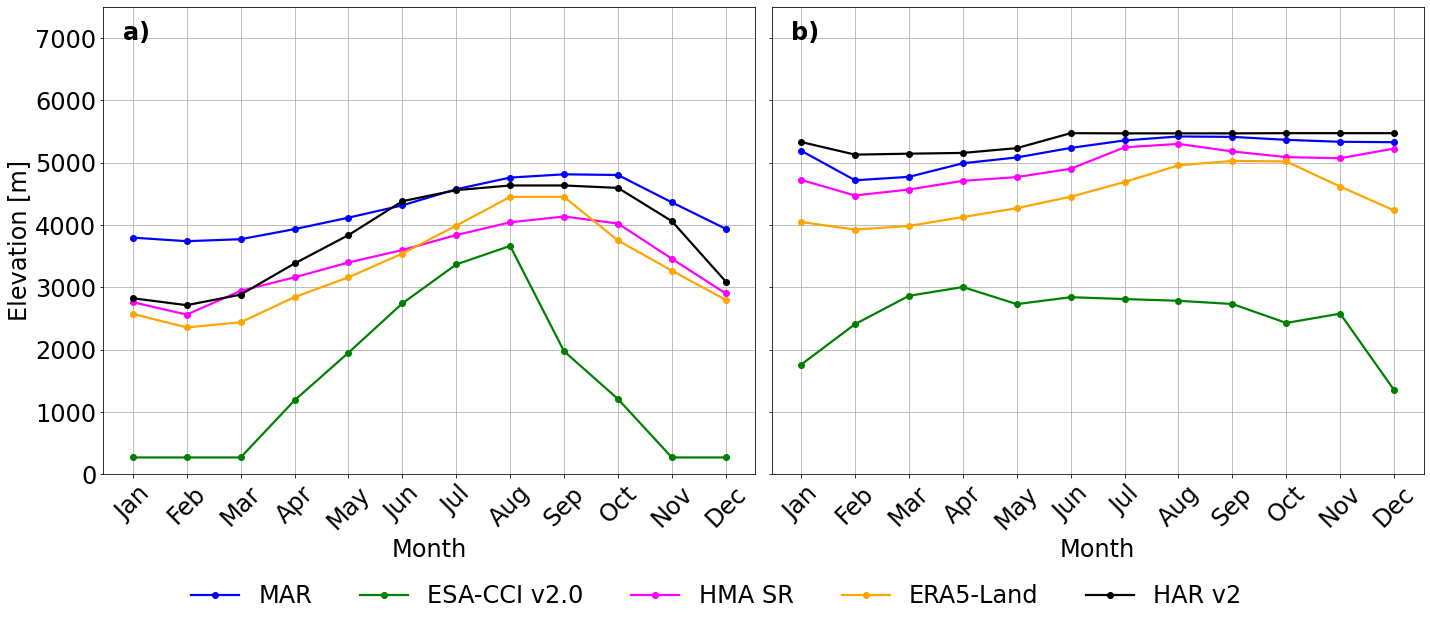

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,8), sharey=True)

# =========================
# LEFT PANEL : GRp
# =========================

# MAR
ax1.plot(ds1['month'], ds1['mean_snowline'],
         marker='o', color="blue", linewidth=2.2, label="MAR")
#ax1.plot(ds1['month'], ds1['mean_bottom10'], "--",
#         color="blue", alpha=0.1)
#ax1.plot(ds1['month'], ds1['mean_top10'], "--",
#         color="blue", alpha=0.1)
#ax1.fill_between(ds1['month'], ds1['mean_bottom10'],
#                 ds1['mean_top10'],
#                 color="lightblue", alpha=0.1)

# ESA CCI
ax1.plot(ds2['month'], ds2['mean_snowline'],
         marker='o', color="green", linewidth=2.2,
         label="ESA-CCI v2.0")
#ax1.fill_between(ds2['month'], ds2['mean_bottom10'],
#                 ds2['mean_top10'],
 #                color="lightgreen", alpha=0.1)

# HMA SR

ax1.plot(ds4['month'], ds4['mean_snowline'],
         marker='o', color="fuchsia", linewidth=2.2,
         label="HMA SR")
#ax1.fill_between(ds4['month'], ds4['mean_bottom10'],
#                 ds4['mean_top10'],
#                 color="pink", alpha=0.1)

# ERA5-Land
ax1.plot(ds3['month'], ds3['mean_snowline'],
         marker='o', color="orange", linewidth=2.2,
         label="ERA5-Land")
#ax1.fill_between(ds3['month'], ds3['mean_bottom10'],
#                 ds3['mean_top10'],
#                 color="orange", alpha=0.1)

# HAR v2
ax1.plot(ds7['month'], ds7['mean_snowline'],
         marker='o', color="black", linewidth=2.2,
         label="HAR v2")
#ax1.fill_between(ds7['month'], ds7['mean_bottom10'],
#                 ds7['mean_top10'],
 #                color="grey", alpha=0.1)

ax1.set_xlabel('Month', fontsize=fz)
ax1.set_xticks(np.arange(1, 13, 1))
ax1.set_xticklabels(
    ['Jan','Feb','Mar','Apr','May','Jun',
     'Jul','Aug','Sep','Oct','Nov','Dec'],
    rotation=45,
    fontsize=fz
)
ax1.tick_params(axis='x', rotation=45, labelsize=fz)
ax1.tick_params(axis='y', labelsize=fz)

ax1.set_ylim(0,6000)
ax1.set_ylabel('Elevation [m]', fontsize=fz)

ax1.text(0.03, 0.97, 'a)', fontsize=fz,fontweight='bold',
         transform=ax1.transAxes,
         horizontalalignment='left',
         verticalalignment='top')

ax1.grid(True)

# =========================
# RIGHT PANEL : GRq
# =========================

# MAR
ax2.plot(ds1_q['month'], ds1_q['mean_snowline'],
         marker='o', color="blue", linewidth=2.2, label="MAR")
#ax2.plot(ds1_q['month'], ds1_q['mean_bottom10'], "--",
#         color="blue", alpha=0.1)
#ax2.plot(ds1_q['month'], ds1_q['mean_top10'], "--",
#         color="blue", alpha=0.1)
#ax2.fill_between(ds1_q['month'], ds1_q['mean_bottom10'],
#                 ds1_q['mean_top10'],
 #                color="lightblue", alpha=0.1)

# ESA CCI
ax2.plot(ds2_q['month'], ds2_q['mean_snowline'],
         marker='o', color="green", linewidth=2.2,
         label="ESA-CCI v2.0")
#ax2.fill_between(ds2_q['month'], ds2_q['mean_bottom10'],
#                 ds2_q['mean_top10'],
#                 color="lightgreen", alpha=0.1)

# HMA SR
ax2.plot(ds4_q['month'], ds4_q['mean_snowline'],
         marker='o', color="fuchsia", linewidth=2.2,
         label="HMA SR")
#ax2.fill_between(ds4_q['month'], ds4_q['mean_bottom10'],
#                 ds4_q['mean_top10'],
 #                color="pink", alpha=0.1)

# ERA5-Land
ax2.plot(ds3_q['month'], ds3_q['mean_snowline'],
         marker='o', color="orange", linewidth=2.2,
         label="ERA5-Land")
#ax2.fill_between(ds3_q['month'], ds3_q['mean_bottom10'],
#                 ds3_q['mean_top10'],
#                 color="orange", alpha=0.1)

# HAR v2
ax2.plot(ds7_q['month'], ds7_q['mean_snowline'],
         marker='o', color="black", linewidth=2.2,
         label="HAR v2")
#ax2.fill_between(ds7_q['month'], ds7_q['mean_bottom10'],
#                 ds7_q['mean_top10'],
#                 color="grey", alpha=0.1)

ax2.set_xlabel('Month', fontsize=fz)
ax2.set_xticks(np.arange(1, 13, 1))
ax2.set_xticklabels(
    ['Jan','Feb','Mar','Apr','May','Jun',
     'Jul','Aug','Sep','Oct','Nov','Dec'],
    rotation=45,
    fontsize=fz
)

ax2.tick_params(axis='x', rotation=45, labelsize=fz)
ax2.tick_params(axis='y', labelsize=fz)

ax2.set_ylim(0,7500)

ax2.text(0.03, 0.97, 'b)', fontsize=fz,fontweight='bold',
         transform=ax2.transAxes,
         horizontalalignment='left',
         verticalalignment='top')

ax2.grid(True)

# =========================
# LEGEND + SAVE
# =========================

handles, labels = ax1.get_legend_handles_labels()

fig.legend(handles, labels,
           loc='lower center',
           ncol=5,
           fontsize=fz,
           frameon=False,
           bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()

plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname=f'FIG7_annual_cycle_snowline_elevation_pamir_nepal_{iyr}-{fyr}_method_ratio_notopbottom'

plt.savefig(f"{plotsDir}{plotname}.png",
            bbox_inches="tight", dpi=300)

print(f"Saved: {plotsDir}{plotname}.png")

plt.show()